# Steps 4–5: Compare preprocessing options

**Conclusion: Use 33 original features, raw monetary values, and no class weighting as the common baseline.** Training-only CV also compares 37 features with migration columns, `log1p`-transformed monetary values, and class weighting. No rows are removed.

These are preliminary results from 30,000 training rows. The held-out test set is not evaluated.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "preprocessing.py").exists() else cwd.parent
assert (repo_root / "src" / "preprocessing.py").exists(), "Run this notebook from the repository root or the notebooks/ directory."
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import (
    MIGRATION_COLUMNS, MONEY_COLUMNS, NUMERIC_COLUMNS,
    build_preprocessor, prepare_xy, select_features,
)

data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    import subprocess
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)
df = pd.read_csv(data_path, skipinitialspace=True)
X, y = prepare_xy(df)
print(f"Rows: {len(X):,}, original features: {X.shape[1]}, positive rate: {y.mean():.2%}")

Rows: 215,574, original features: 40, positive rate: 8.61%


## 1. Stratified 80/20 split

**Decision: Hold out 20% for final evaluation.** Fit imputation, transformations, and mutual information (MI) on training data only.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "positive_count": [int(y_train.sum()), int(y_test.sum())],
    "positive_rate_pct": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"])
display(split_summary)
assert len(X_train) + len(X_test) == 215_574

,rows,positive_count,positive_rate_pct
train,172459,14853,8.61
test,43115,3713,8.61


## 2. Preprocessing pipeline and one-hot feature count

**Pipeline: Median-impute and standardize numeric columns; impute categorical columns with `Missing` and one-hot encode them.** Allow unseen categories and fit on training data only.

In [3]:
feature_counts = []
for include_migration in (False, True):
    X_variant = select_features(X_train, include_migration)
    preprocessor = build_preprocessor(X_variant, log_money=False)
    transformed = preprocessor.fit_transform(X_variant)
    feature_counts.append({
        "migration": "keep" if include_migration else "drop",
        "original_features": X_variant.shape[1],
        "onehot_output_columns": transformed.shape[1],
        "sparse": bool(hasattr(transformed, "tocsr")),
    })
display(pd.DataFrame(feature_counts))

,migration,original_features,onehot_output_columns,sparse
0,drop,33,441,True
1,keep,37,471,True


## 3. Compare options on the same training sample and five folds

**Goal: Compare average precision (AP) on the same 30,000 rows and five folds.** Logistic regression is a preliminary reference model; its results need not generalize to other classifiers.

In [4]:
X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=42
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for include_migration in (False, True):
    X_variant = select_features(X_dev, include_migration)
    for log_money in (False, True):
        for class_weight in (None, "balanced"):
            model = Pipeline([
                ("preprocess", build_preprocessor(X_variant, log_money)),
                ("classifier", LogisticRegression(
                    solver="liblinear", max_iter=1000, class_weight=class_weight,
                    random_state=42,
                )),
            ])
            scores = cross_validate(
                model, X_variant, y_dev, cv=folds,
                scoring={"AP": "average_precision", "ROC_AUC": "roc_auc"},
                n_jobs=1, error_score="raise",
            )
            results.append({
                "migration": "keep" if include_migration else "drop",
                "money": "log1p" if log_money else "raw",
                "class_weight": class_weight or "none",
                "AP_mean": scores["test_AP"].mean(),
                "AP_sd": scores["test_AP"].std(),
                "ROC_AUC_mean": scores["test_ROC_AUC"].mean(),
                "fit_seconds_mean": scores["fit_time"].mean(),
            })
comparison = pd.DataFrame(results).sort_values("AP_mean", ascending=False)
display(comparison.round(4).reset_index(drop=True))
print(f"Random-ranking AP baseline: {y_dev.mean():.4f}")

,migration,money,class_weight,AP_mean,AP_sd,ROC_AUC_mean,fit_seconds_mean
0,drop,raw,none,0.6048,0.0076,0.9199,0.3270
1,keep,raw,none,0.6044,0.0070,0.9197,0.2768
2,keep,raw,balanced,0.5977,0.0090,0.9179,0.3474
3,drop,raw,balanced,0.5975,0.0095,0.9183,0.3033
4,drop,log1p,none,0.5927,0.0153,0.9181,0.2885
5,keep,log1p,none,0.5922,0.0149,0.9179,0.2673
6,drop,log1p,balanced,0.5834,0.0139,0.9159,0.3141
7,keep,log1p,balanced,0.5834,0.0133,0.9155,0.3700


Random-ranking AP baseline: 0.0861


## 4. Rank original features by mutual information

**Decision: Rank the 33 original features, not individual one-hot columns.** Mark categorical variables as discrete and use training rows only.

In [5]:
X_mi = select_features(X_dev, include_migration=False).copy()
cat_cols = [c for c in X_mi.columns if c not in NUMERIC_COLUMNS]
X_mi[NUMERIC_COLUMNS] = SimpleImputer(strategy="median").fit_transform(X_mi[NUMERIC_COLUMNS])
cat_imputed = SimpleImputer(strategy="constant", fill_value="Missing").fit_transform(X_mi[cat_cols])
X_mi[cat_cols] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(cat_imputed)
discrete_mask = [c in cat_cols for c in X_mi.columns]
mi_scores = mutual_info_classif(
    X_mi, y_dev, discrete_features=discrete_mask, random_state=42, n_neighbors=3
)
mi_ranking = pd.DataFrame({"feature": X_mi.columns, "MI_score": mi_scores})
mi_ranking = mi_ranking.sort_values("MI_score", ascending=False).reset_index(drop=True)
display(mi_ranking)

,feature,MI_score
0,detailed_occupation_recode,0.067893
1,major_occupation_code,0.052412
2,education,0.047368
3,detailed_industry_recode,0.033437
4,capital_gains,0.032297
5,dividends_from_stocks,0.031464
6,weeks_worked_in_year,0.031036
7,major_industry_code,0.030929
8,class_of_worker,0.023358
9,age,0.022934


## 5. One-hot dimensionality and PCA

**Decision: Use PCA for exploration, not in the baseline pipeline.** On 30,000 training rows, inspect explained variance and plots by income class and survey year. Standardized numeric and 0/1 dummy columns do not have equal variance.

,explained_variance,components_needed,encoded_columns
0,0.80,31,440
1,0.90,63,440
2,0.95,99,440
3,0.99,191,440


Largest absolute loadings:


,PC1,PC2
0,other_numeric__weeks_worked_in_year,money__dividends_from_stocks
1,other_numeric__num_persons_worked_for_employer,money__capital_gains
2,other_numeric__age,other_numeric__age
3,categorical__major_industry_code_Not in univer...,money__capital_losses
4,categorical__major_occupation_code_Not in univ...,categorical__detailed_household_summary_in_hou...


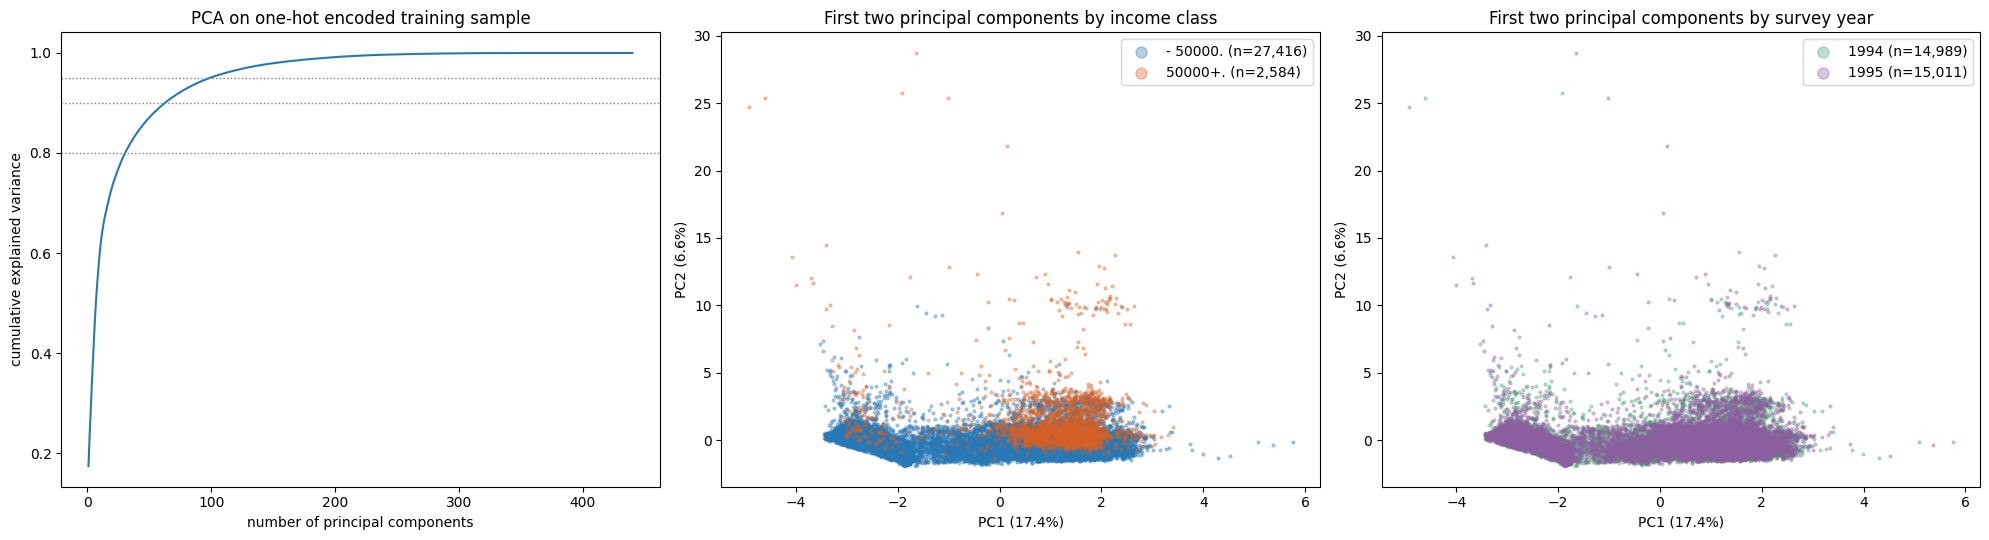

In [6]:
X_pca_source = select_features(X_dev, include_migration=False)
pca_preprocessor = build_preprocessor(X_pca_source, log_money=False)
X_encoded = pca_preprocessor.fit_transform(X_pca_source).toarray()
pca = PCA(random_state=42).fit(X_encoded)
cumulative = np.cumsum(pca.explained_variance_ratio_)
display(pd.DataFrame({
    "explained_variance": [0.80, 0.90, 0.95, 0.99],
    "components_needed": [int(np.searchsorted(cumulative, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)],
    "encoded_columns": X_encoded.shape[1],
}))

feature_names = pca_preprocessor.get_feature_names_out()
loadings = pd.DataFrame({
    f"PC{i + 1}": pd.Series(pca.components_[i], index=feature_names)
    .abs().sort_values(ascending=False).head(5).index
    for i in range(2)
})
print("Largest absolute loadings:")
display(loadings)

components = pca.transform(X_encoded)[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, color="#2878B5")
for t in (0.80, 0.90, 0.95):
    axes[0].axhline(t, color="grey", linestyle=":", linewidth=1)
axes[0].set_xlabel("number of principal components")
axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA on one-hot encoded training sample")
for label, name, color in ((0, "- 50000.", "#2878B5"), (1, "50000+.", "#D66027")):
    mask = y_dev.to_numpy() == label
    axes[1].scatter(components[mask, 0], components[mask, 1], s=4, alpha=0.35,
                    color=color, label=f"{name} (n={mask.sum():,})")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("First two principal components by income class")
axes[1].legend(markerscale=4)
year_values = X_pca_source["year"].to_numpy()
for year, color in (("94", "#4C9F70"), ("95", "#8E5EA2")):
    mask = year_values == year
    axes[2].scatter(components[mask, 0], components[mask, 1], s=4, alpha=0.35,
                    color=color, label=f"19{year} (n={mask.sum():,})")
axes[2].set_xlabel(axes[1].get_xlabel())
axes[2].set_ylabel(axes[1].get_ylabel())
axes[2].set_title("First two principal components by survey year")
axes[2].legend(markerscale=4)
fig.tight_layout()
plt.show()

## Decision notes

**Conclusion: Use 33 features, raw monetary values, and no class weighting as the common baseline.**

- **Columns:** Drop the four migration columns because all 1995 rows are missing them, not because of the negligible LR AP difference (0.0004). Also drop the constant column and two year-specific columns.
- **Monetary values:** LR AP is 0.6048 with raw values versus 0.5927 with `log1p`. Keep raw values as the baseline; assess other classifiers separately.
- **Class weights:** LR AP is 0.6048 without weighting versus 0.5975 with `balanced`. Use no weighting as the baseline, without assuming the result applies to other models.
- **Dimensionality:** One-hot encoding yields 441 columns on the full training set and 440 on the 30,000-row sample. PCA needs 63 components for 90% explained variance. The survey-year bands are no longer visible after removing the two year-specific columns. Do not include PCA in the baseline pipeline.

All results are preliminary and training-only. In later CV, fit preprocessing within each training fold.